In [ ]:
# Student No : 22422481
# Surname and Initials : Duma N 
# Subject code : TPRO200


#Dataset 1 Link – https://github.com/afrith/crime-stats 
#Official SAPS origin: https://saps.gov.za/services/crimestats.php (Excel quarterly releases
#Geographic unit: SAPS police precinct / station (≈40 in Ekurhuleni).
#Time span: January 2020 – September 2025 (monthly).
#Variables: Station name, crime category (hierarchical: Contact crime → Murder, Sexual offences/Rape, Assault GBH, etc.), year, month, count.
#Granularity: Station × month × category.
#Limitations: Counts only (no victim gender in public files); under-reporting is known; station boundaries change occasionally (cleaned in this repo); no point-level incident locations.


#Dataset 2 – Contextual / geographic / demographic information

#Source A (preferred, already aligned): Same GitHub repo – police_stations.csv + .gpkg contain Census 2022 population, area (km²), local municipality, district municipality, province codes, and clean polygon boundaries.
#Source B (supplementary): Stats SA Census 2022 / SuperWeb (https://superweb.statssa.gov.za) and ward-level small-area estimates (https://www.statssa.gov.za/?p=18967). Ekurhuleni GIS portal: https://gis.ekurhuleni.gov.za/ (wards, streets, facilities).
#Geographic unit: Police precinct (primary) + local municipality / ward for context.
#Time span: Census 2022 (static) + mid-year estimates where available.
#Variables: Population, area, density, municipality codes, basic socio-demographic indicators if pulled from SuperWeb.
#Granularity: Precinct-level population & area (pre-aligned).
#Limitations: Population is a 2022 snapshot (not time-varying); wards ≠ precincts, so never join naively.

##     How the datasets are integrated / aligned 

#Filter both files to Ekurhuleni / Gauteng stations that belong to the City of Ekurhuleni local municipality (using the municipality codes already present in police_stations.csv).
#Join crime counts to station attributes on exact station name (the cleaned names are consistent).
#Compute rates = (crime count / population) × 100 000.
#Spatial analysis uses the matching .gpkg polygons only – never assume ward = precinct.
#If you later want finer wards, use spatial overlay (point-in-polygon or areal interpolation) only after projecting both layers to the same CRS; do not do a simple attribute join on names.

#          PROBLEM DEFINATION 

#Recent high-profile discoveries of women in Kempton Park and other parts of Ekurhuleni have heightened concern about spatial concentration of violent crime against women.  
#Raw SAPS counts show volume but do not automatically reveal:
#- where risk is concentrated (hotspots),
#- how patterns change over time,
#- which combinations of geographic, demographic and environmental factors are associated with higher recorded violence.

In [1]:
# Core libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Geospatial
import geopandas as gpd
from shapely.geometry import Point

# Machine learning
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, 
                             roc_auc_score, precision_recall_curve, f1_score)
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA

# Stats & time series helpers
from scipy import stats
import statsmodels.api as sm

# Display settings
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [6]:
# Direct raw URLs from the cleaned GitHub repository
CRIME_URL = "https://raw.githubusercontent.com/afrith/crime-stats/main/crime-stats.csv"
STATIONS_URL = "https://raw.githubusercontent.com/afrith/crime-stats/main/police_stations.csv"
# Spatial file
# GPKG_URL = "https://github.com/afrith/crime-stats/raw/main/police_stations.gpkg"

print("Loading crime-stats.csv ...")
crime = pd.read_csv(CRIME_URL)
print(f"Crime shape: {crime.shape}")
print(crime.head(3))
print("\nColumns:", crime.columns.tolist())

print("\nLoading police_stations.csv ...")
stations = pd.read_csv(STATIONS_URL)
print(f"Stations shape: {stations.shape}")
print(stations.head(3))
print("\nColumns:", stations.columns.tolist())

Loading stations...
Stations shape: (1167, 7)
       code            name muni_code dc_code prov_code  population  area_km2
0  PD210001  St Francis Bay     EC108    DC10        EC        9626    117.68
1  PD210002    Jeffreys Bay     EC108    DC10        EC       36704    260.57
2  PD210003      Humansdorp     EC108    DC10        EC       30198   1339.42

Loading crime-stats.csv (this is ~200 MB – may take 1–3 minutes)...
Crime shape: (3541428, 8)
  province station_code    station_name crime_code crime_name  year  month  \
0       EC     PD210001  St Francis Bay          1     Murder  2020      1   
1       EC     PD210001  St Francis Bay          1     Murder  2020      2   
2       EC     PD210001  St Francis Bay          1     Murder  2020      3   

   crime_count  
0            0  
1            0  
2            0  

Columns: ['province', 'station_code', 'station_name', 'crime_code', 'crime_name', 'year', 'month', 'crime_count']


In [7]:
# Inspect municipality / province columns to find the correct filter
print("Unique provinces:", stations['province'].unique() if 'province' in stations.columns else "check columns")
print("\nSample of local municipality / district columns:")
print(stations[['name', 'local_municipality', 'district_municipality', 'province']].head(10) 
      if all(c in stations.columns for c in ['name','local_municipality','district_municipality','province']) 
      else stations.head())

# Typical filter for Ekurhuleni (adjust after inspection – common values are "City of Ekurhuleni" or code "EKU")
# First look at unique values
if 'local_municipality' in stations.columns:
    print("\nUnique local municipalities containing 'Ekurhuleni' or 'East Rand':")
    print(stations[stations['local_municipality'].str.contains('Ekurhuleni|East Rand', case=False, na=False)]
          ['local_municipality'].unique())

Unique provinces: check columns

Sample of local municipality / district columns:
       code            name muni_code dc_code prov_code  population  area_km2
0  PD210001  St Francis Bay     EC108    DC10        EC        9626    117.68
1  PD210002    Jeffreys Bay     EC108    DC10        EC       36704    260.57
2  PD210003      Humansdorp     EC108    DC10        EC       30198   1339.42
3  PD210004    Storms River     EC109    DC10        EC       13147    694.58
4  PD210005       Kareedouw     EC109    DC10        EC       10273   1233.49


In [8]:
# Filter to City of Ekurhuleni
eku_stations = stations[stations['muni_code'] == 'EKU'].copy()
print(f"Number of Ekurhuleni police stations: {len(eku_stations)}")
print("\nStation list:")
print(eku_stations[['code', 'name', 'population', 'area_km2']].sort_values('name').to_string())

# Quick density
eku_stations['density'] = eku_stations['population'] / eku_stations['area_km2']
print("\nTop 5 densest precincts:")
print(eku_stations.nlargest(5, 'density')[['name', 'population', 'area_km2', 'density']])

Number of Ekurhuleni police stations: 36

Station list:
         code                   name  population  area_km2
359  PD797020             Actonville       73116      9.34
353  PD797014               Alberton       89972     49.31
363  PD797024            Bedfordview       48158     27.51
362  PD797023                 Benoni      112851     98.76
356  PD797017               Boksburg       62646     45.47
361  PD797022         Boksburg North       35409     45.51
349  PD797010           Brackendowns       49644     43.57
352  PD797013                Brakpan       79098    169.21
368  PD797029            Crystalpark       58732     67.74
364  PD797025               Daveyton      161315     15.05
350  PD797011              Dawn Park      141917     52.96
342  PD797003                 Duduza      113351     49.18
347  PD797008              Dunnottar       11070     49.87
341  PD797002               Edenpark      218396     25.14
366  PD797027               Edenvale       67703     22.59


In [9]:
print("Crime data columns:", crime.columns.tolist())
print("\nSample rows:")
print(crime.head(3))

print("\nUnique crime categories (first 30):")
print(crime['category'].unique()[:30] if 'category' in crime.columns else crime.columns)

# Check year/month range
print("\nYear range:", crime['year'].min(), "–", crime['year'].max() if 'year' in crime.columns else "check columns")
print("Month range:", sorted(crime['month'].unique()) if 'month' in crime.columns else "check")

Crime data columns: ['province', 'station_code', 'station_name', 'crime_code', 'crime_name', 'year', 'month', 'crime_count']

Sample rows:
  province station_code    station_name crime_code crime_name  year  month  \
0       EC     PD210001  St Francis Bay          1     Murder  2020      1   
1       EC     PD210001  St Francis Bay          1     Murder  2020      2   
2       EC     PD210001  St Francis Bay          1     Murder  2020      3   

   crime_count  
0            0  
1            0  
2            0  

Unique crime categories (first 30):
Index(['province', 'station_code', 'station_name', 'crime_code', 'crime_name',
       'year', 'month', 'crime_count'],
      dtype='object')

Year range: 2020 – 2025
Month range: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]


In [10]:
# Ekurhuleni stations
eku_stations = stations[stations['muni_code'] == 'EKU'].copy()
print(f"Ekurhuleni stations: {len(eku_stations)}")

# Create matching keys
eku_names = set(eku_stations['name'].str.strip().str.lower())
eku_codes = set(eku_stations['code'].str.strip())

# Filter crime data
crime['station_clean'] = crime['station_name'].str.strip().str.lower()
eku_crime = crime[
    (crime['station_clean'].isin(eku_names)) | 
    (crime['station_code'].isin(eku_codes))
].copy()

print(f"\nEkurhuleni crime records: {len(eku_crime):,}")
print("Stations matched:", eku_crime['station_name'].nunique())
print("\nSample of matched stations:")
print(sorted(eku_crime['station_name'].unique())[:15])

Ekurhuleni stations: 36

Ekurhuleni crime records: 109,296
Stations matched: 36

Sample of matched stations:
['Actonville', 'Alberton', 'Bedfordview', 'Benoni', 'Boksburg', 'Boksburg North', 'Brackendowns', 'Brakpan', 'Crystalpark', 'Daveyton', 'Dawn Park', 'Duduza', 'Dunnottar', 'Edenpark', 'Edenvale']


In [11]:
# Contact crimes most relevant as a proxy for women-safety risk
# (SAPS public data does not currently publish victim gender at station level)
CONTACT_CRIMES = [
    'Murder',
    'Rape',
    'Sexual offences',
    'Sexual assault',
    'Attempted sexual offences',
    'Contact sexual offences',
    'Attempted murder',
    'Assault with the intent to inflict grievous bodily harm',
    'Common assault',
    'Common robbery',
    'Robbery with aggravating circumstances',
    'Robbery at residential premises',
    'Robbery at non-residential premises',
    'Carjacking',
    'Kidnapping',
    'Abduction'
]

# Keep only these categories for Ekurhuleni
eku_contact = eku_crime[eku_crime['crime_name'].isin(CONTACT_CRIMES)].copy()
print(f"Contact-crime records: {len(eku_contact):,}")
print("\nCounts by crime type:")
print(eku_contact.groupby('crime_name')['crime_count'].sum().sort_values(ascending=False))

Contact-crime records: 39,744

Counts by crime type:
crime_name
Robbery with aggravating circumstances                     66498
Common assault                                             62124
Assault with the intent to inflict grievous bodily harm    54770
Sexual offences                                            16129
Carjacking                                                 15304
Common robbery                                             13823
Rape                                                       12719
Robbery at residential premises                            10466
Kidnapping                                                  9554
Murder                                                      9310
Attempted murder                                            9022
Robbery at non-residential premises                         8698
Sexual assault                                              2643
Attempted sexual offences                                    470
Contact sexual offences   

In [12]:
# Monthly total contact crimes per station
monthly = (eku_contact
           .groupby(['station_code', 'station_name', 'year', 'month'], as_index=False)
           ['crime_count'].sum()
           .rename(columns={'crime_count': 'contact_count'}))

# Add population & area from stations table
monthly = monthly.merge(
    eku_stations[['code', 'name', 'population', 'area_km2']],
    left_on='station_code', right_on='code', how='left'
)

# Safety rate per 100 000 population
monthly['contact_rate'] = (monthly['contact_count'] / monthly['population']) * 100_000

# Create a proper date column
monthly['date'] = pd.to_datetime(monthly[['year', 'month']].assign(day=1))

print(monthly.head())
print(f"\nShape: {monthly.shape}")
print(f"Date range: {monthly['date'].min().date()} → {monthly['date'].max().date()}")

  station_code station_name  year  month  contact_count      code        name  \
0     PD797001   Zonkizizwe  2020      1             40  PD797001  Zonkizizwe   
1     PD797001   Zonkizizwe  2020      2             48  PD797001  Zonkizizwe   
2     PD797001   Zonkizizwe  2020      3             45  PD797001  Zonkizizwe   
3     PD797001   Zonkizizwe  2020      4             27  PD797001  Zonkizizwe   
4     PD797001   Zonkizizwe  2020      5             27  PD797001  Zonkizizwe   

   population  area_km2  contact_rate       date  
0       72653     51.47     55.056226 2020-01-01  
1       72653     51.47     66.067471 2020-02-01  
2       72653     51.47     61.938254 2020-03-01  
3       72653     51.47     37.162953 2020-04-01  
4       72653     51.47     37.162953 2020-05-01  

Shape: (2484, 11)
Date range: 2020-01-01 → 2025-09-01


In [13]:
# Overall summary by station (whole period)
station_summary = (monthly
                   .groupby(['station_name', 'population', 'area_km2'], as_index=False)
                   .agg(total_contact=('contact_count', 'sum'),
                        mean_monthly_rate=('contact_rate', 'mean'),
                        max_monthly_rate=('contact_rate', 'max'))
                   .sort_values('mean_monthly_rate', ascending=False))

print("Top 10 stations by average monthly contact-crime rate (per 100k):")
print(station_summary.head(10).to_string(index=False))

print("\nBottom 5 (lowest average rate):")
print(station_summary.tail(5).to_string(index=False))

Top 10 stations by average monthly contact-crime rate (per 100k):
         station_name  population  area_km2  total_contact  mean_monthly_rate  max_monthly_rate
OR Tambo Intl Airport         291     16.96            304        1514.019622       3780.068729
       Boksburg North       35409     45.51           7778         318.350243        454.686662
         Kempton Park       66629     98.58          12936         281.376369        387.218779
            Germiston       74357     41.70          11530         224.728606        301.249378
      Olifantsfontein       36196    196.89           4586         183.621859        348.104763
              Elsburg       56139     41.01           5653         145.936936        242.255829
             Boksburg       62646     45.47           6245         144.474103        212.304058
          Bedfordview       48158     27.51           4684         140.961124        209.726318
             Alberton       89972     49.31           8602         138

In [14]:

# HOTSPOT DEFINITION (transparent & justified)
# 
# I defined a geographic-time unit (station-month) as a HOTSPOT
# if its contact-crime rate is in the top 20 % of all station-months
# in Ekurhuleni during the study period.

# Justification:
# - Rate (not raw count) adjusts for population size → fairer comparison
# - 80th percentile is a common, transparent threshold used in crime analysis
# - Easy to communicate to decision-makers
# -


threshold = monthly['contact_rate'].quantile(0.80)
print(f"Hotspot threshold (80th percentile of contact_rate): {threshold:.1f} per 100 000")

monthly['is_hotspot'] = (monthly['contact_rate'] >= threshold).astype(int)

print("\nHotspot prevalence:")
print(monthly['is_hotspot'].value_counts(normalize=True).round(3))
print(f"\nNumber of hotspot station-months: {monthly['is_hotspot'].sum():,}")

Hotspot threshold (80th percentile of contact_rate): 146.4 per 100 000

Hotspot prevalence:
is_hotspot
0    0.799
1    0.201
Name: proportion, dtype: float64

Number of hotspot station-months: 499


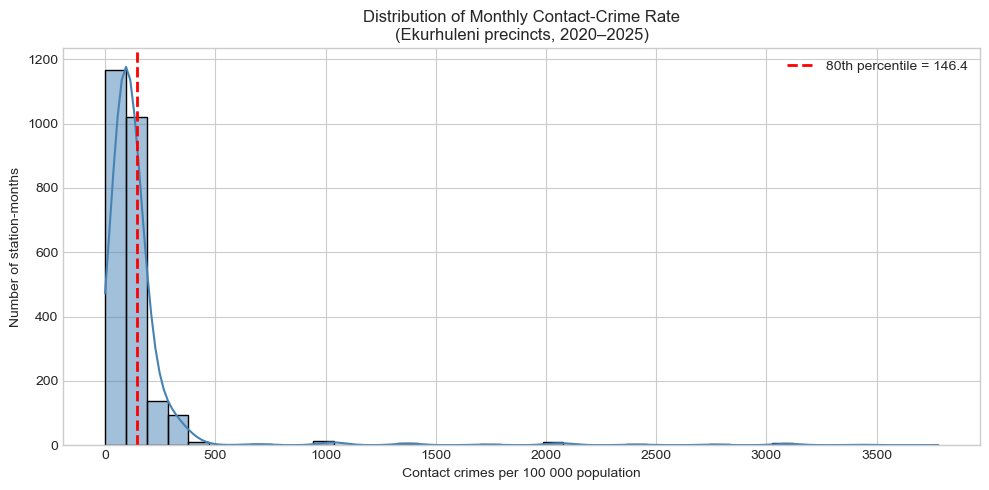

In [15]:
plt.figure(figsize=(10, 5))
sns.histplot(monthly['contact_rate'], bins=40, kde=True, color='steelblue')
plt.axvline(threshold, color='red', linestyle='--', linewidth=2, 
            label=f'80th percentile = {threshold:.1f}')
plt.title('Distribution of Monthly Contact-Crime Rate\n(Ekurhuleni precincts, 2020–2025)')
plt.xlabel('Contact crimes per 100 000 population')
plt.ylabel('Number of station-months')
plt.legend()
plt.tight_layout()
plt.show()

In [16]:
# Make sure we have the monthly dataset from previous cells
# (re-create if needed)
CONTACT_CRIMES = [
    'Murder', 'Rape', 'Sexual offences', 'Sexual assault',
    'Attempted sexual offences', 'Contact sexual offences',
    'Attempted murder',
    'Assault with the intent to inflict grievous bodily harm',
    'Common assault', 'Common robbery',
    'Robbery with aggravating circumstances',
    'Robbery at residential premises', 'Robbery at non-residential premises',
    'Carjacking', 'Kidnapping', 'Abduction'
]

eku_contact = eku_crime[eku_crime['crime_name'].isin(CONTACT_CRIMES)].copy()

monthly = (eku_contact
           .groupby(['station_code', 'station_name', 'year', 'month'], as_index=False)
           ['crime_count'].sum()
           .rename(columns={'crime_count': 'contact_count'}))

monthly = monthly.merge(
    eku_stations[['code', 'name', 'population', 'area_km2']],
    left_on='station_code', right_on='code', how='left'
)

monthly['contact_rate'] = (monthly['contact_count'] / monthly['population']) * 100_000
monthly['date'] = pd.to_datetime(monthly[['year', 'month']].assign(day=1))

print("Monthly dataset ready:", monthly.shape)
print(monthly.head(3))

Monthly dataset ready: (2484, 11)
  station_code station_name  year  month  contact_count      code        name  \
0     PD797001   Zonkizizwe  2020      1             40  PD797001  Zonkizizwe   
1     PD797001   Zonkizizwe  2020      2             48  PD797001  Zonkizizwe   
2     PD797001   Zonkizizwe  2020      3             45  PD797001  Zonkizizwe   

   population  area_km2  contact_rate       date  
0       72653     51.47     55.056226 2020-01-01  
1       72653     51.47     66.067471 2020-02-01  
2       72653     51.47     61.938254 2020-03-01  


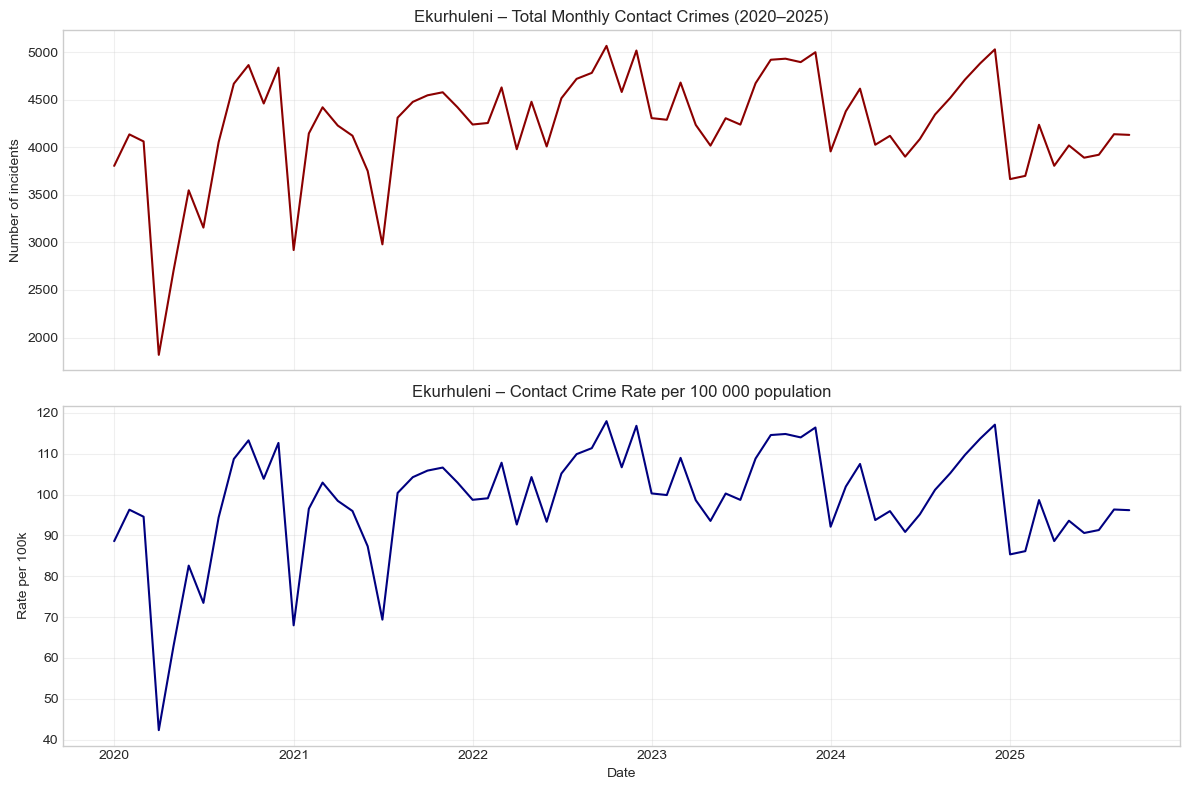

In [17]:
# City-wide monthly total and rate
city_monthly = (monthly
                .groupby('date', as_index=False)
                .agg(total_contact=('contact_count', 'sum'),
                     total_pop=('population', 'sum')))
city_monthly['city_rate'] = (city_monthly['total_contact'] / city_monthly['total_pop']) * 100_000

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(city_monthly['date'], city_monthly['total_contact'], color='darkred', linewidth=1.5)
axes[0].set_title('Ekurhuleni – Total Monthly Contact Crimes (2020–2025)')
axes[0].set_ylabel('Number of incidents')
axes[0].grid(True, alpha=0.3)

axes[1].plot(city_monthly['date'], city_monthly['city_rate'], color='navy', linewidth=1.5)
axes[1].set_title('Ekurhuleni – Contact Crime Rate per 100 000 population')
axes[1].set_ylabel('Rate per 100k')
axes[1].set_xlabel('Date')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

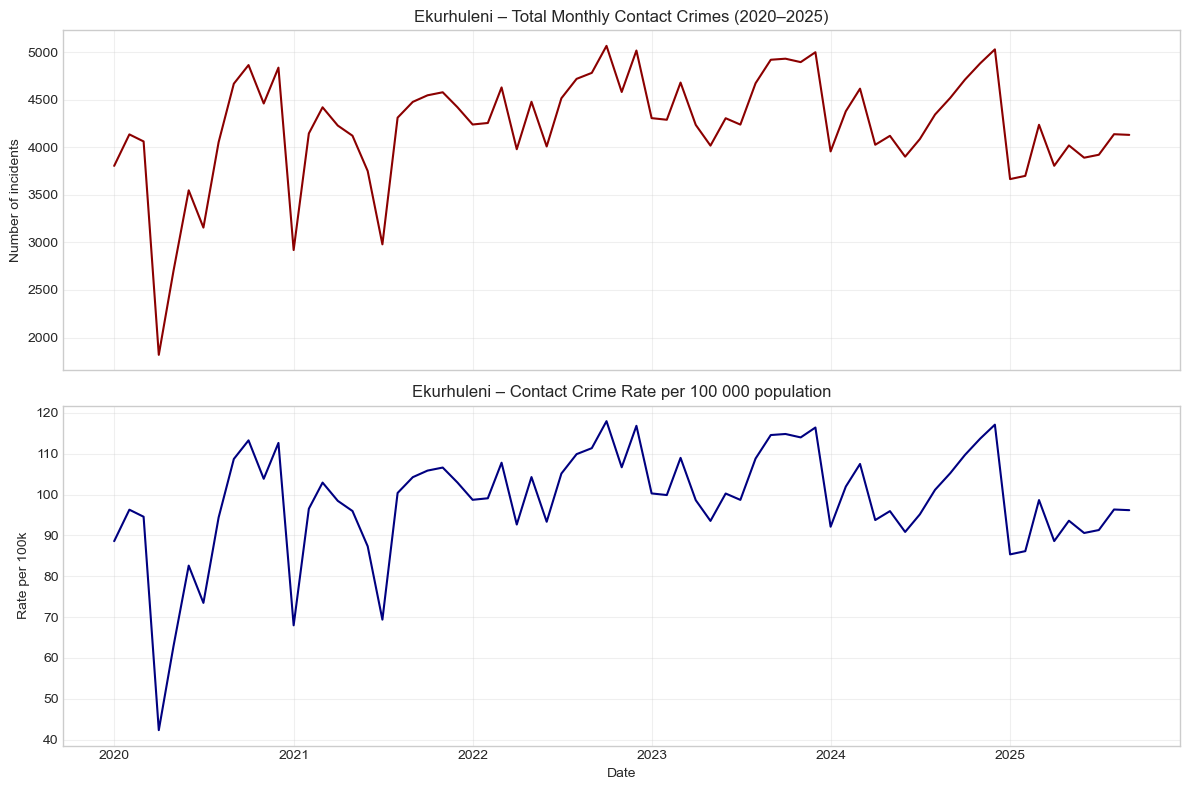

In [18]:
# City-wide monthly total and rate
city_monthly = (monthly
                .groupby('date', as_index=False)
                .agg(total_contact=('contact_count', 'sum'),
                     total_pop=('population', 'sum')))
city_monthly['city_rate'] = (city_monthly['total_contact'] / city_monthly['total_pop']) * 100_000

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(city_monthly['date'], city_monthly['total_contact'], color='darkred', linewidth=1.5)
axes[0].set_title('Ekurhuleni – Total Monthly Contact Crimes (2020–2025)')
axes[0].set_ylabel('Number of incidents')
axes[0].grid(True, alpha=0.3)

axes[1].plot(city_monthly['date'], city_monthly['city_rate'], color='navy', linewidth=1.5)
axes[1].set_title('Ekurhuleni – Contact Crime Rate per 100 000 population')
axes[1].set_ylabel('Rate per 100k')
axes[1].set_xlabel('Date')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

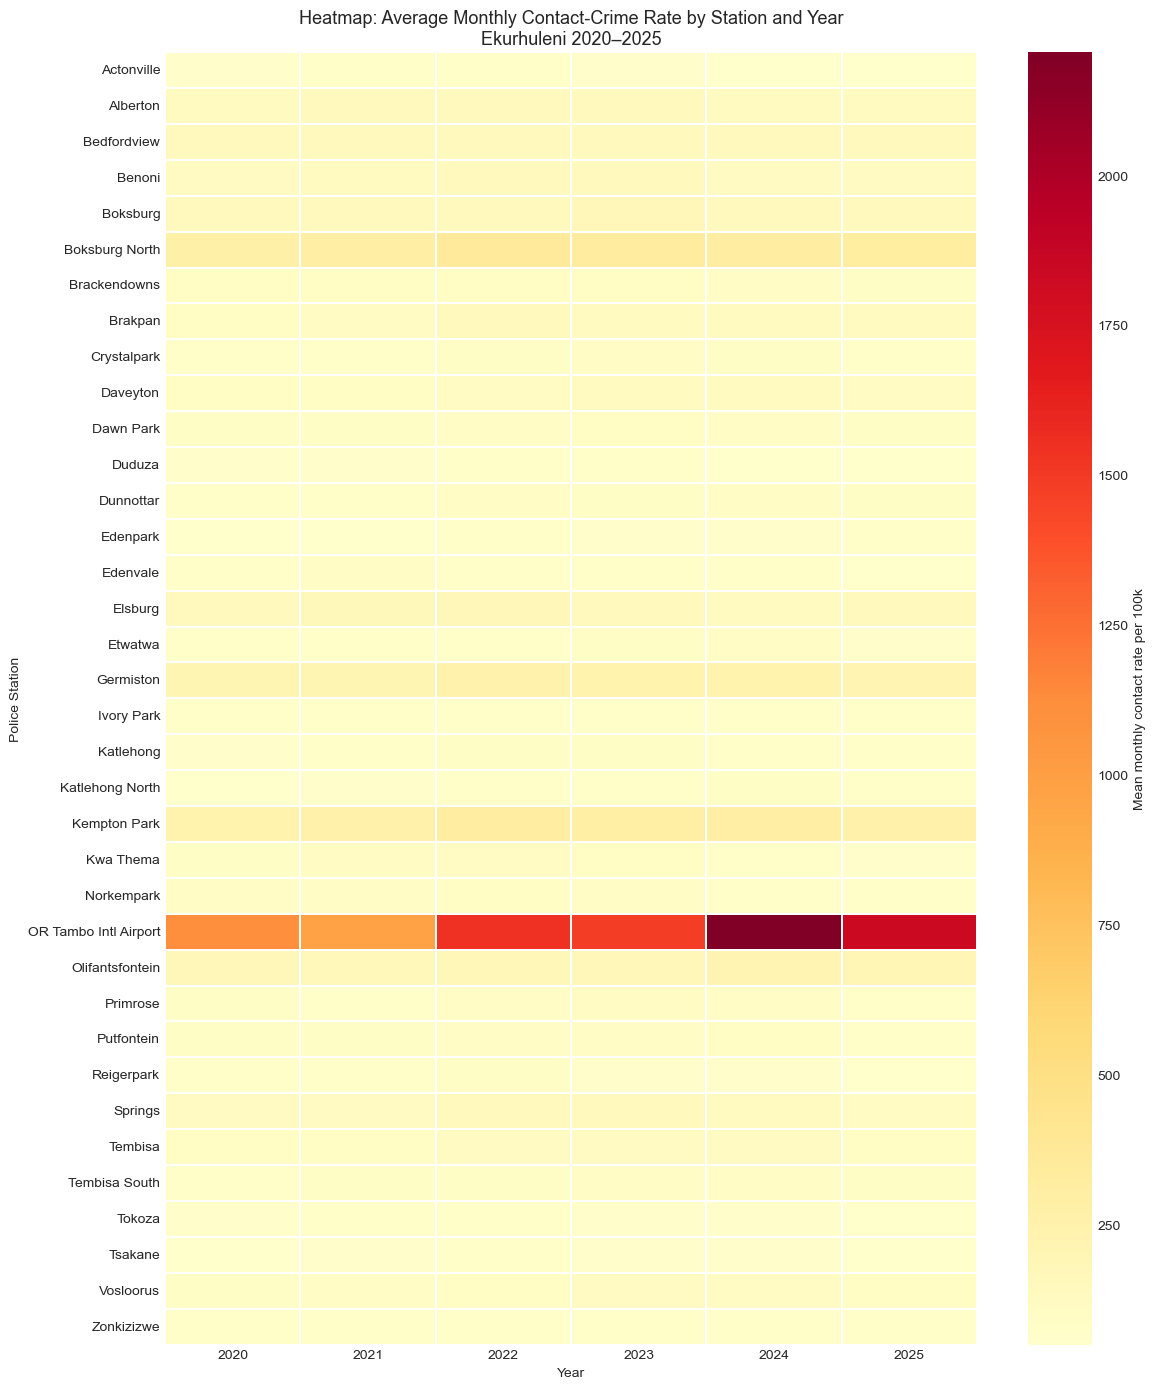

In [19]:
# Pivot: stations vs years (mean monthly rate)
heat_data = (monthly
             .groupby(['station_name', 'year'])['contact_rate']
             .mean()
             .unstack(level='year')
             .sort_index())

plt.figure(figsize=(12, 14))
sns.heatmap(heat_data, cmap='YlOrRd', annot=False, linewidths=0.3,
            cbar_kws={'label': 'Mean monthly contact rate per 100k'})
plt.title('Heatmap: Average Monthly Contact-Crime Rate by Station and Year\nEkurhuleni 2020–2025', fontsize=13)
plt.xlabel('Year')
plt.ylabel('Police Station')
plt.tight_layout()
plt.show()

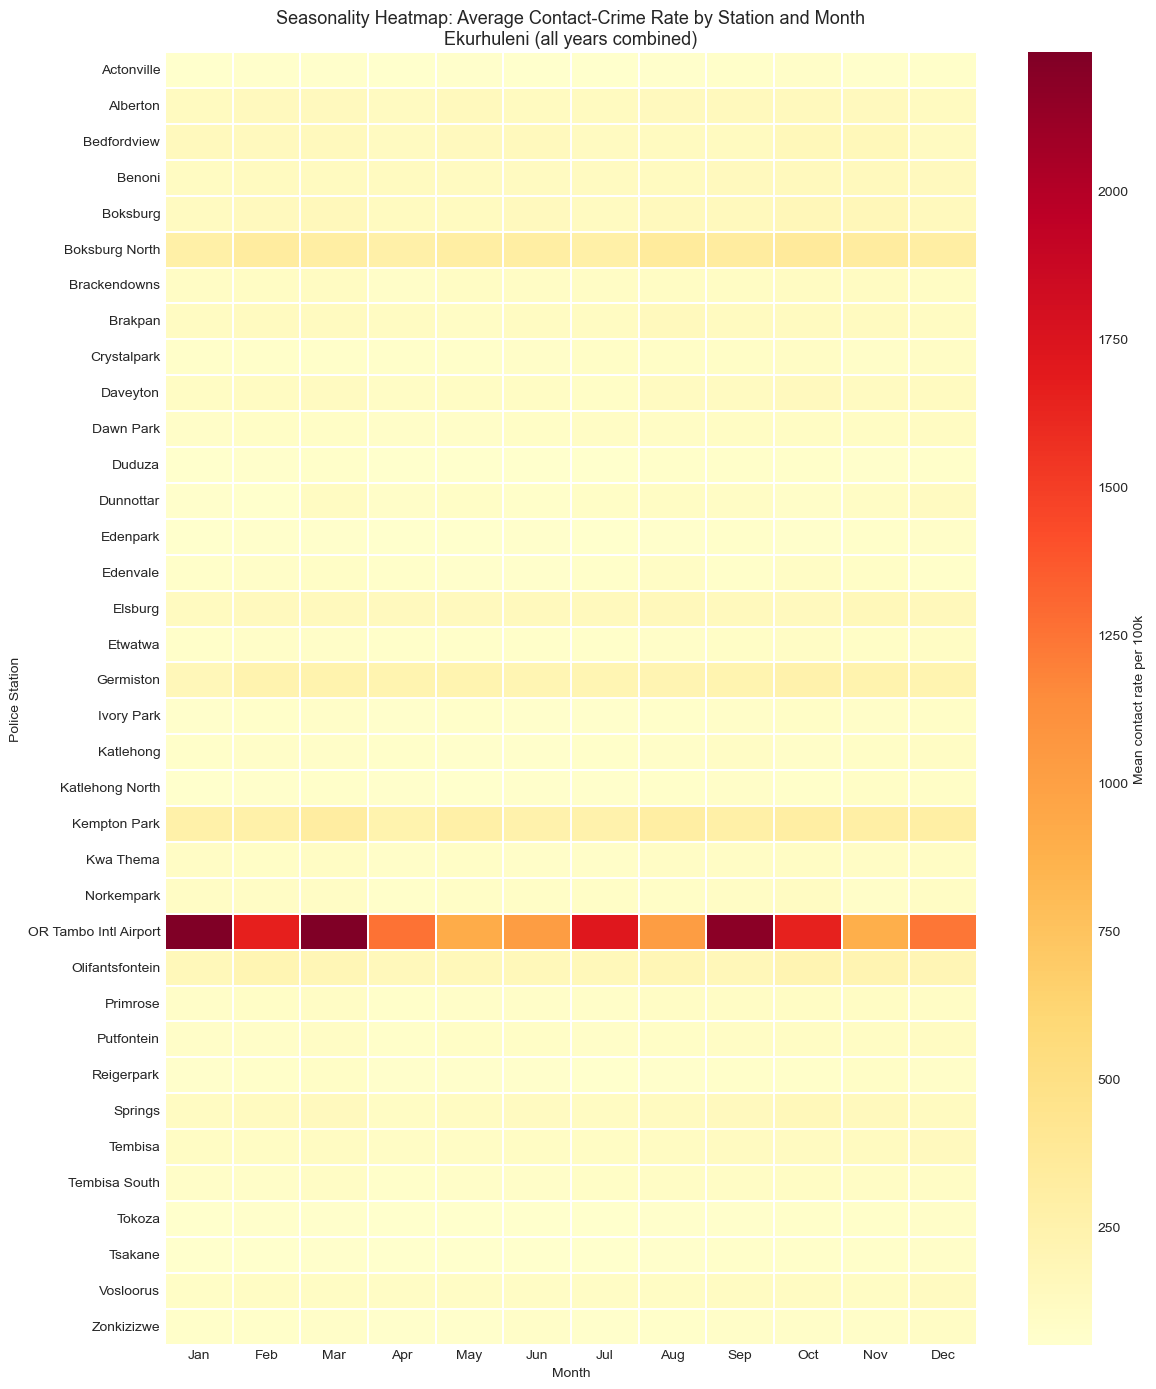

In [20]:
# Average rate by station and calendar month (across all years)
season = (monthly
          .groupby(['station_name', 'month'])['contact_rate']
          .mean()
          .unstack(level='month')
          .sort_index())

# Order months nicely
season = season.reindex(columns=range(1, 13))
season.columns = ['Jan','Feb','Mar','Apr','May','Jun',
                  'Jul','Aug','Sep','Oct','Nov','Dec']

plt.figure(figsize=(12, 14))
sns.heatmap(season, cmap='YlOrRd', annot=False, linewidths=0.3,
            cbar_kws={'label': 'Mean contact rate per 100k'})
plt.title('Seasonality Heatmap: Average Contact-Crime Rate by Station and Month\nEkurhuleni (all years combined)', fontsize=13)
plt.xlabel('Month')
plt.ylabel('Police Station')
plt.tight_layout()
plt.show()

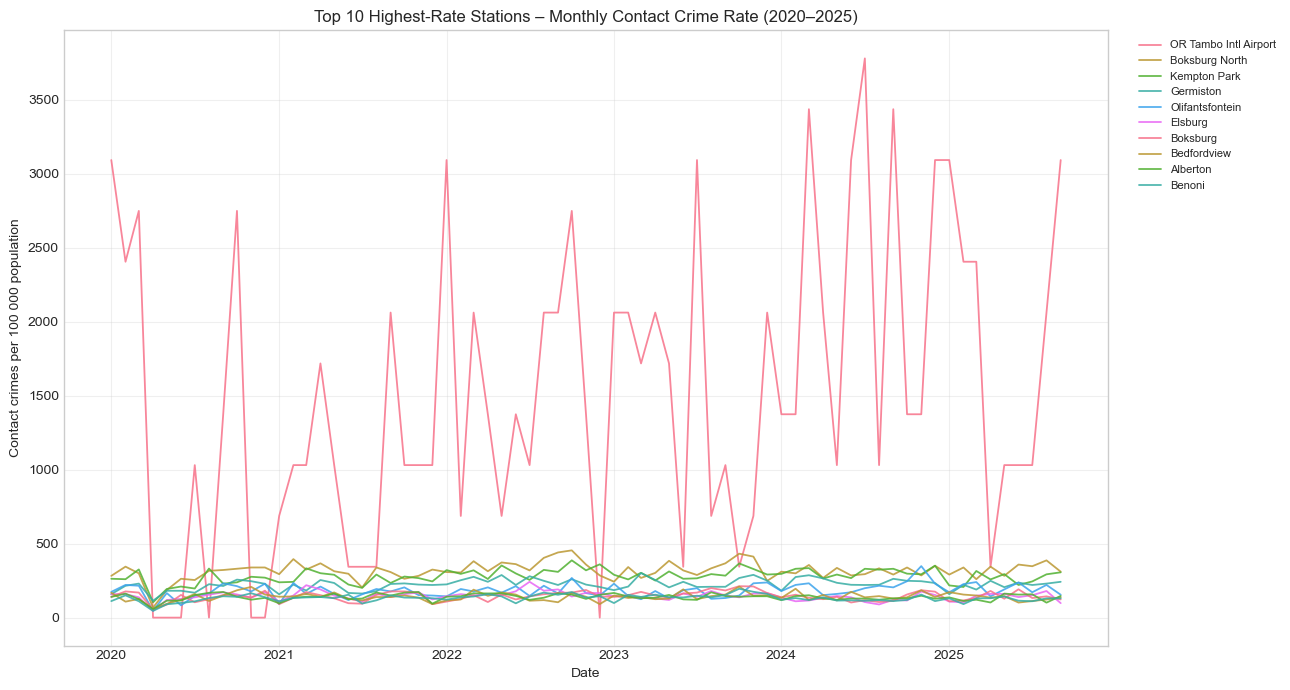

In [21]:
# Identify top 10 stations by overall average rate
top10 = (monthly
         .groupby('station_name')['contact_rate']
         .mean()
         .nlargest(10)
         .index.tolist())

top10_data = monthly[monthly['station_name'].isin(top10)]

plt.figure(figsize=(13, 7))
for station in top10:
    subset = top10_data[top10_data['station_name'] == station]
    plt.plot(subset['date'], subset['contact_rate'], label=station, linewidth=1.3, alpha=0.85)

plt.title('Top 10 Highest-Rate Stations – Monthly Contact Crime Rate (2020–2025)')
plt.ylabel('Contact crimes per 100 000 population')
plt.xlabel('Date')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

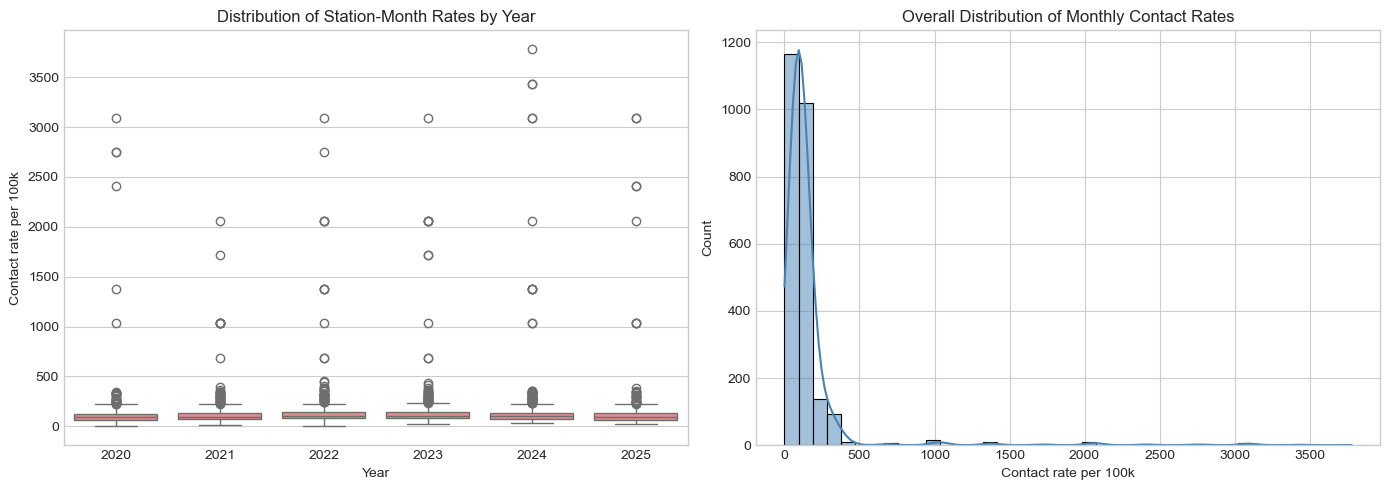

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot of rates by year
sns.boxplot(data=monthly, x='year', y='contact_rate', ax=axes[0], color='lightcoral')
axes[0].set_title('Distribution of Station-Month Rates by Year')
axes[0].set_ylabel('Contact rate per 100k')
axes[0].set_xlabel('Year')

# Histogram of all rates
sns.histplot(monthly['contact_rate'], bins=40, kde=True, ax=axes[1], color='steelblue')
axes[1].set_title('Overall Distribution of Monthly Contact Rates')
axes[1].set_xlabel('Contact rate per 100k')

plt.tight_layout()
plt.show()

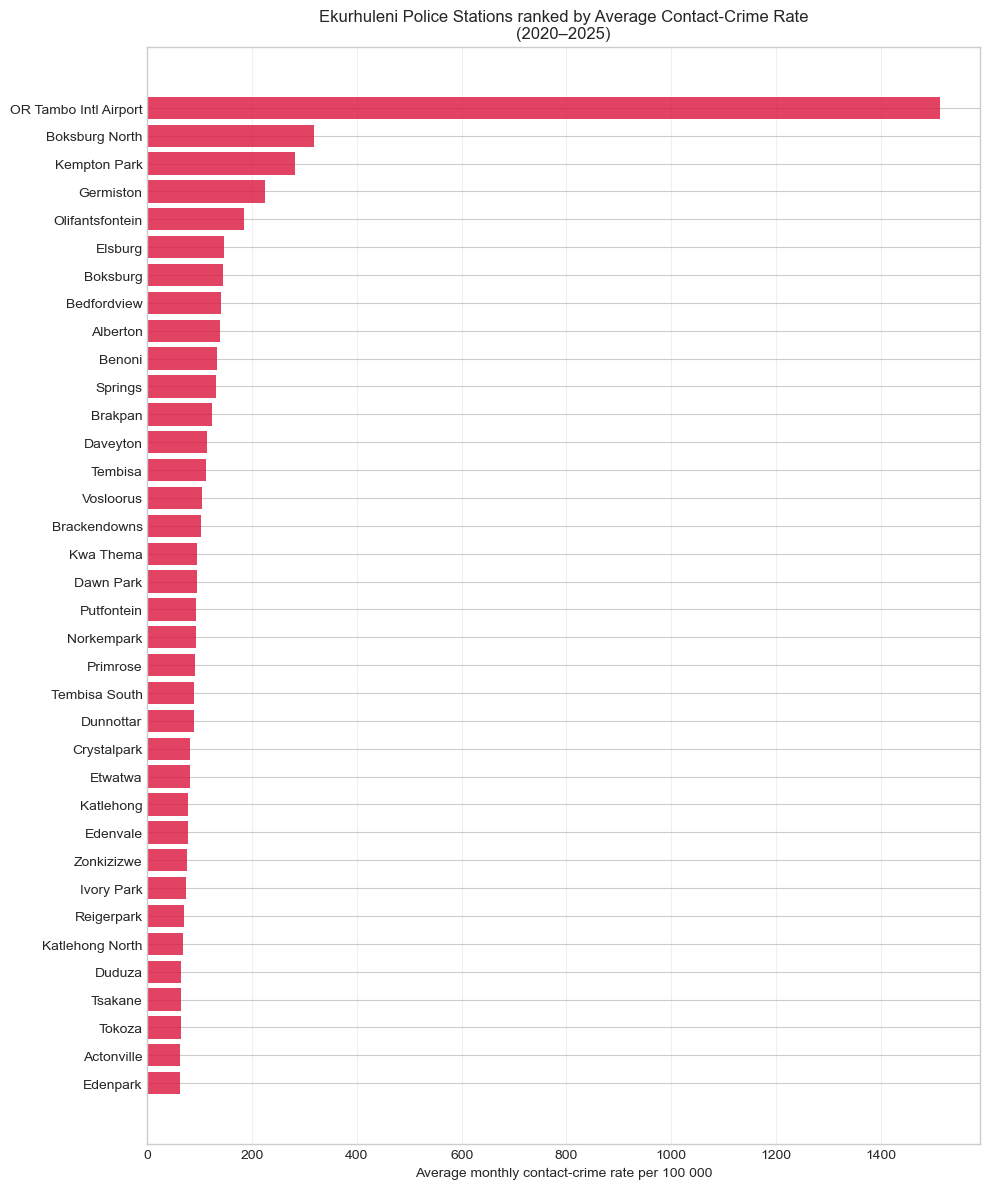

In [23]:
station_avg = (monthly
               .groupby('station_name')
               .agg(mean_rate=('contact_rate', 'mean'),
                    total_incidents=('contact_count', 'sum'),
                    population=('population', 'first'))
               .sort_values('mean_rate', ascending=True))

plt.figure(figsize=(10, 12))
plt.barh(station_avg.index, station_avg['mean_rate'], color='crimson', alpha=0.8)
plt.xlabel('Average monthly contact-crime rate per 100 000')
plt.title('Ekurhuleni Police Stations ranked by Average Contact-Crime Rate\n(2020–2025)')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

GeoPackage downloaded.


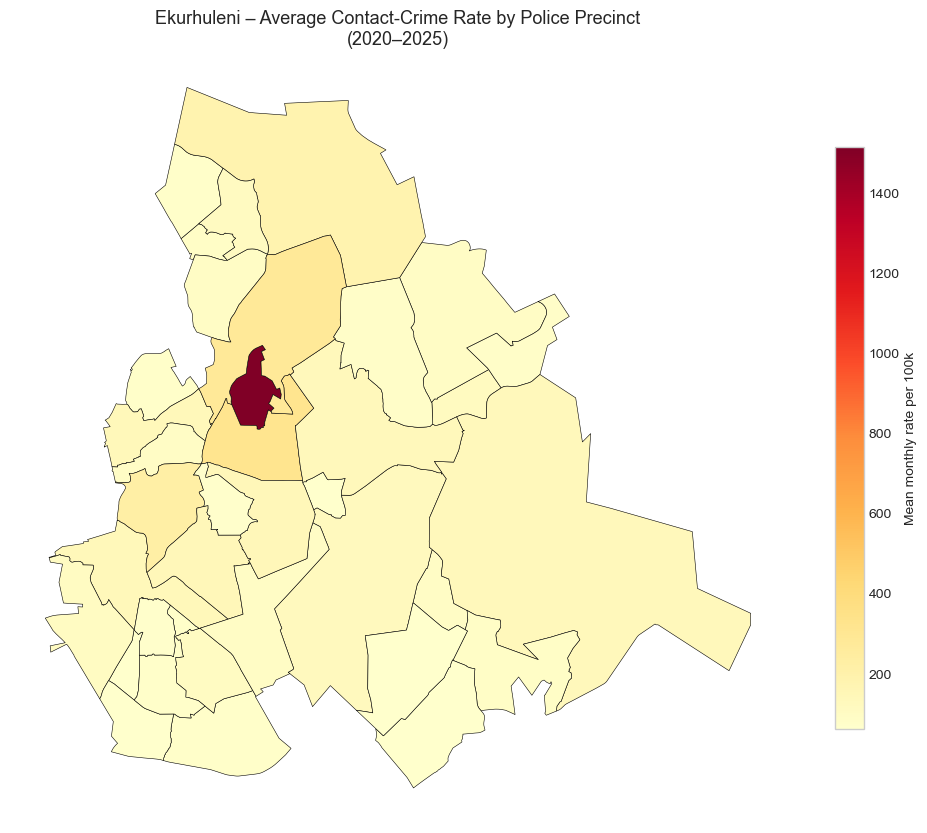

In [24]:
# I  Downloaded the GeoPackage from tthe GITrepository
import urllib.request
gpkg_url = "https://github.com/afrith/crime-stats/raw/main/police_stations.gpkg"
gpkg_path = "police_stations.gpkg"

try:
    urllib.request.urlretrieve(gpkg_url, gpkg_path)
    print("GeoPackage downloaded.")
except Exception as e:
    print("Download failed:", e)
    print("You can manually download from: https://github.com/afrith/crime-stats")

# Read and filter to Ekurhuleni
gdf = gpd.read_file(gpkg_path)
gdf_eku = gdf[gdf['muni_code'] == 'EKU'].copy()

# Join average rate
avg_rate = monthly.groupby('station_code')['contact_rate'].mean().reset_index()
gdf_eku = gdf_eku.merge(avg_rate, left_on='code', right_on='station_code', how='left')

# Simple choropleth
fig, ax = plt.subplots(1, 1, figsize=(10, 10))
gdf_eku.plot(column='contact_rate', cmap='YlOrRd', legend=True,
             edgecolor='black', linewidth=0.4, ax=ax,
             legend_kwds={'label': 'Mean monthly rate per 100k', 'shrink': 0.6})
ax.set_title('Ekurhuleni – Average Contact-Crime Rate by Police Precinct\n(2020–2025)', fontsize=13)
ax.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
#     FEARRURE ENGENEERING 

In [26]:


df = monthly.copy()

# --- Re-create the hotspot label (same definition as before) ---
threshold = df['contact_rate'].quantile(0.80)
df['is_hotspot'] = (df['contact_rate'] >= threshold).astype(int)
print(f"Hotspot threshold used: {threshold:.1f} per 100k")
print(f"Hotspot prevalence: {df['is_hotspot'].mean():.3f}")

# --- Temporal features ---
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['quarter'] = df['date'].dt.quarter
df['is_winter'] = df['month'].isin([6, 7, 8]).astype(int)          # Jun-Aug
df['is_festive'] = df['month'].isin([11, 12, 1]).astype(int)       # Nov-Jan

# --- Lag features (previous month) ---
df = df.sort_values(['station_code', 'date'])
df['lag1_count'] = df.groupby('station_code')['contact_count'].shift(1)
df['lag1_rate']  = df.groupby('station_code')['contact_rate'].shift(1)

# --- Rolling features (3-month) ---
df['roll3_mean_rate'] = (df.groupby('station_code')['contact_rate']
                           .transform(lambda x: x.rolling(3, min_periods=1).mean()))
df['roll3_std_rate']  = (df.groupby('station_code')['contact_rate']
                           .transform(lambda x: x.rolling(3, min_periods=1).std()))

# --- Station-level static features ---
df['log_population'] = np.log1p(df['population'])
df['density'] = df['population'] / df['area_km2']
df['log_density'] = np.log1p(df['density'])

# Drop rows with missing lags (first month of each station)
df_model = df.dropna(subset=['lag1_rate', 'roll3_std_rate']).copy()

print("\nModel-ready shape:", df_model.shape)
print("Hotspot balance in model data:")
print(df_model['is_hotspot'].value_counts(normalize=True).round(3))

Hotspot threshold used: 146.4 per 100k
Hotspot prevalence: 0.201

Model-ready shape: (2448, 22)
Hotspot balance in model data:
is_hotspot
0    0.799
1    0.201
Name: proportion, dtype: float64


In [27]:
feature_cols = [
    'lag1_rate', 'lag1_count',
    'roll3_mean_rate', 'roll3_std_rate',
    'log_population', 'log_density',
    'month', 'quarter', 'is_winter', 'is_festive',
    'year'
]

X = df_model[feature_cols]
y = df_model['is_hotspot']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"Train size: {X_train.shape[0]}  |  Test size: {X_test.shape[0]}")
print(f"Train hotspot rate: {y_train.mean():.3f}  |  Test hotspot rate: {y_test.mean():.3f}")

Train size: 1836  |  Test size: 612
Train hotspot rate: 0.200  |  Test hotspot rate: 0.201


In [28]:
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

print("=== Random Forest Results ===")
print(classification_report(y_test, y_pred_rf, digits=3))
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob_rf):.3f}")

=== Random Forest Results ===
              precision    recall  f1-score   support

           0      0.970     0.933     0.951       489
           1      0.768     0.886     0.823       123

    accuracy                          0.923       612
   macro avg      0.869     0.909     0.887       612
weighted avg      0.929     0.923     0.925       612

ROC-AUC: 0.981


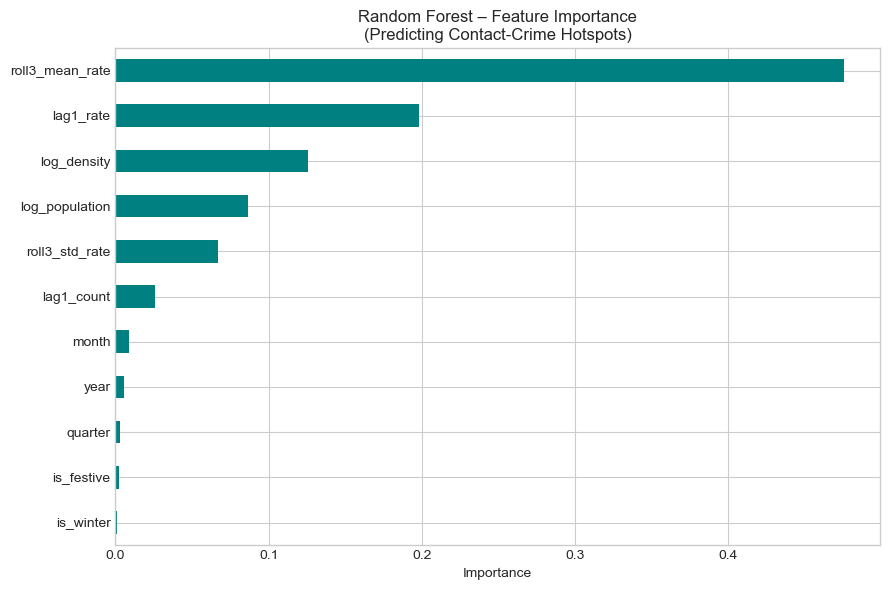

roll3_mean_rate    0.475551
lag1_rate          0.198417
log_density        0.125638
log_population     0.086681
roll3_std_rate     0.067247
lag1_count         0.025864
month              0.008760
year               0.005273
quarter            0.003045
is_festive         0.002371
is_winter          0.001152
dtype: float64


In [29]:
imp = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=True)

plt.figure(figsize=(9, 6))
imp.plot(kind='barh', color='teal')
plt.title('Random Forest – Feature Importance\n(Predicting Contact-Crime Hotspots)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

print(imp.sort_values(ascending=False))

In [30]:
gb = GradientBoostingClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.08,
    random_state=42
)

gb.fit(X_train, y_train)
y_pred_gb = gb.predict(X_test)
y_prob_gb = gb.predict_proba(X_test)[:, 1]

print("=== Gradient Boosting Results ===")
print(classification_report(y_test, y_pred_gb, digits=3))
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob_gb):.3f}")

=== Gradient Boosting Results ===
              precision    recall  f1-score   support

           0      0.954     0.967     0.960       489
           1      0.862     0.813     0.837       123

    accuracy                          0.936       612
   macro avg      0.908     0.890     0.899       612
weighted avg      0.935     0.936     0.936       612

ROC-AUC: 0.984


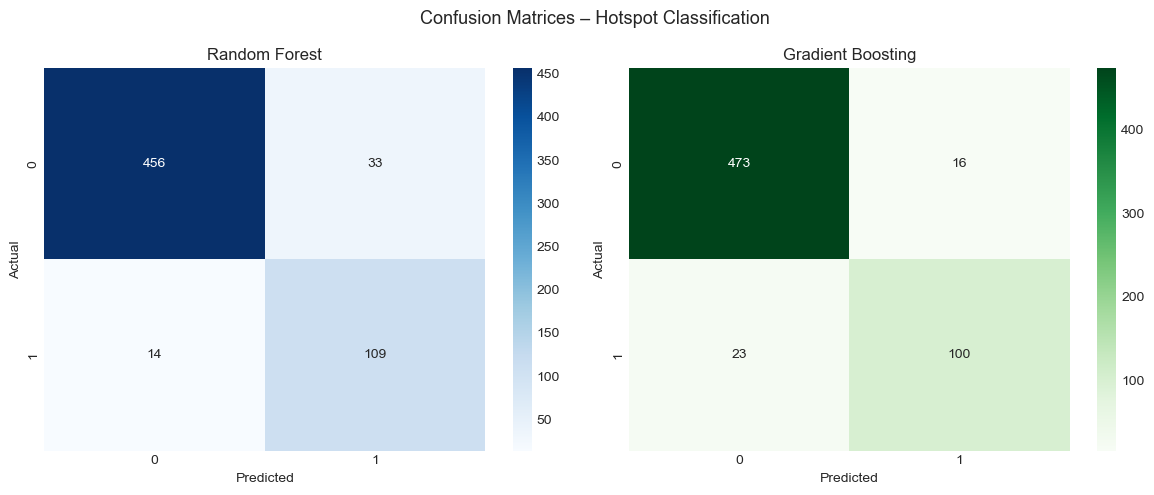

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Random Forest')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(confusion_matrix(y_test, y_pred_gb), annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('Gradient Boosting')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.suptitle('Confusion Matrices – Hotspot Classification', fontsize=13)
plt.tight_layout()
plt.show()

In [32]:
# Rank stations by % of months they were hotspots + average rate
station_hotspot_profile = (df_model
    .groupby('station_name')
    .agg(
        hotspot_months = ('is_hotspot', 'sum'),
        total_months   = ('is_hotspot', 'count'),
        mean_rate      = ('contact_rate', 'mean'),
        population     = ('population', 'first')
    )
)
station_hotspot_profile['hotspot_pct'] = (
    station_hotspot_profile['hotspot_months'] / station_hotspot_profile['total_months'] * 100
)

# Exclude OR Tambo (tiny population distorts rates) and rank
candidates = station_hotspot_profile[station_hotspot_profile['population'] > 5000]
top3 = candidates.sort_values(['hotspot_pct', 'mean_rate'], ascending=False).head(3)

print("=== Three selected hotspot precincts for deeper comparison ===")
print(top3[['hotspot_pct', 'mean_rate', 'population', 'hotspot_months']].round(1))

=== Three selected hotspot precincts for deeper comparison ===
                hotspot_pct  mean_rate  population  hotspot_months
station_name                                                      
Boksburg North         98.5      318.9       35409              67
Kempton Park           98.5      281.7       66629              67
Germiston              98.5      225.7       74357              67


Selected stations: ['Boksburg North', 'Kempton Park', 'Germiston']


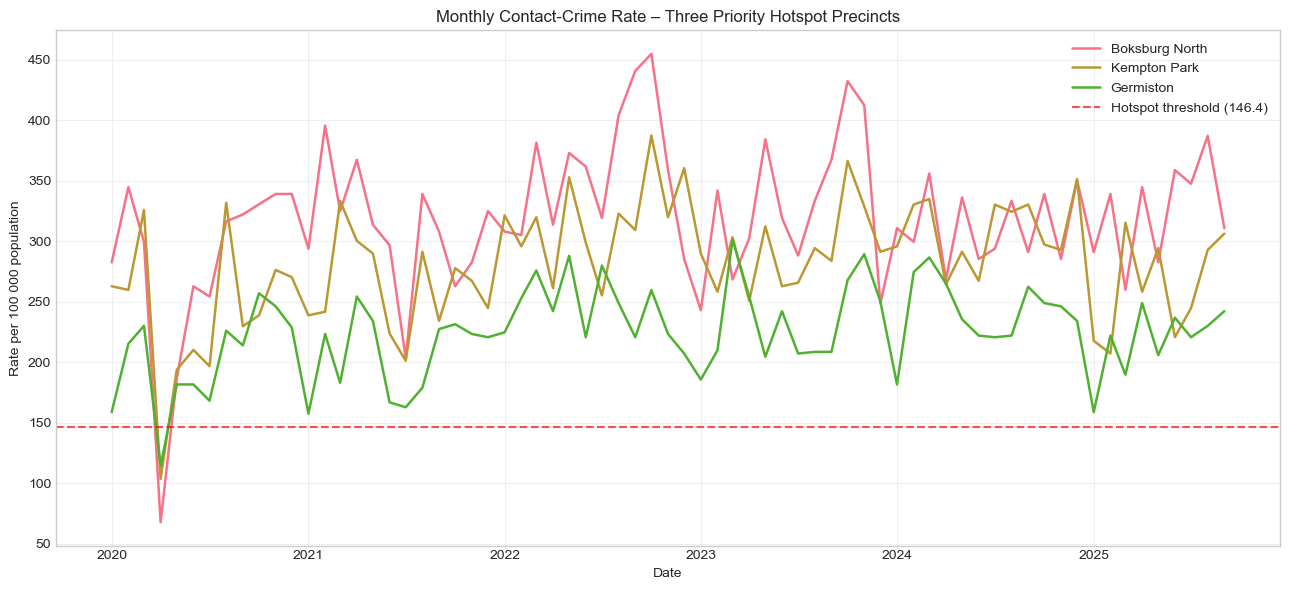

In [33]:
selected = top3.index.tolist()
print("Selected stations:", selected)

sel_data = monthly[monthly['station_name'].isin(selected)]

plt.figure(figsize=(13, 6))
for st in selected:
    subset = sel_data[sel_data['station_name'] == st]
    plt.plot(subset['date'], subset['contact_rate'], label=st, linewidth=1.8)

plt.axhline(146.4, color='red', linestyle='--', alpha=0.7, label='Hotspot threshold (146.4)')
plt.title('Monthly Contact-Crime Rate – Three Priority Hotspot Precincts')
plt.ylabel('Rate per 100 000 population')
plt.xlabel('Date')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Selected stations: ['Boksburg North', 'Kempton Park', 'Germiston']


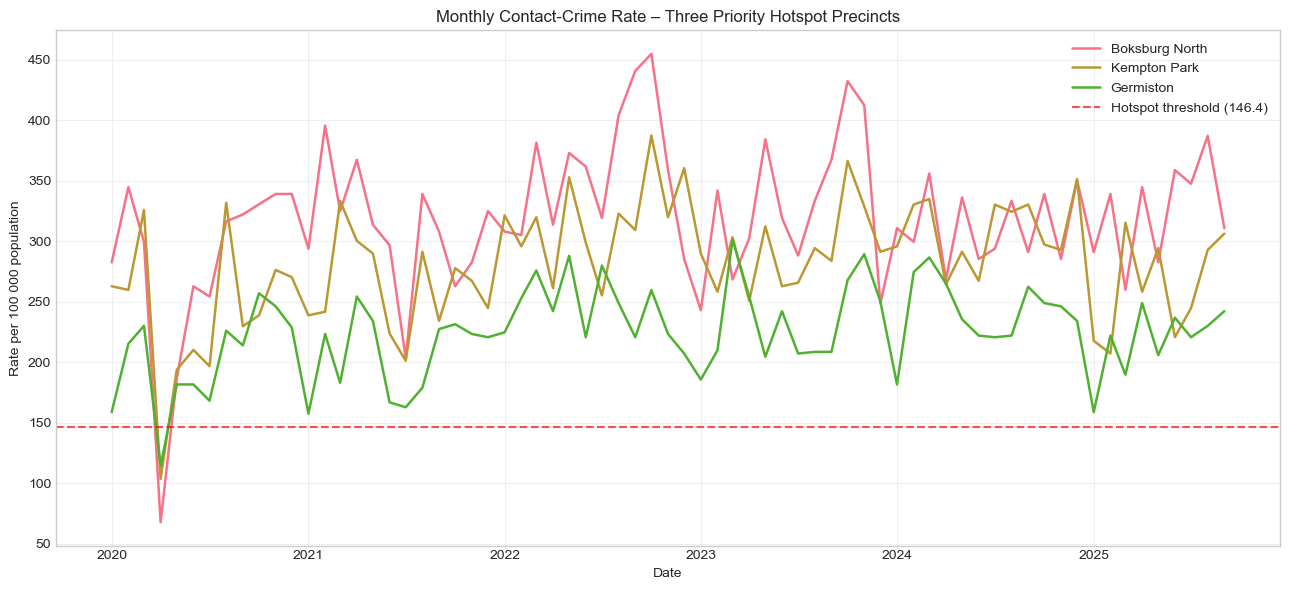

In [34]:
selected = top3.index.tolist()
print("Selected stations:", selected)

sel_data = monthly[monthly['station_name'].isin(selected)]

plt.figure(figsize=(13, 6))
for st in selected:
    subset = sel_data[sel_data['station_name'] == st]
    plt.plot(subset['date'], subset['contact_rate'], label=st, linewidth=1.8)

plt.axhline(146.4, color='red', linestyle='--', alpha=0.7, label='Hotspot threshold (146.4)')
plt.title('Monthly Contact-Crime Rate – Three Priority Hotspot Precincts')
plt.ylabel('Rate per 100 000 population')
plt.xlabel('Date')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [35]:
# Create station-level profile for clustering
profile = (df_model
    .groupby('station_name')
    .agg(
        mean_rate = ('contact_rate', 'mean'),
        std_rate  = ('contact_rate', 'std'),
        hotspot_pct = ('is_hotspot', 'mean'),
        log_pop   = ('log_population', 'first'),
        log_dens  = ('log_density', 'first')
    )
    .dropna()
)

# Scale and cluster
scaler = StandardScaler()
X_prof = scaler.fit_transform(profile)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
profile['cluster'] = kmeans.fit_predict(X_prof)

print("Cluster sizes:")
print(profile['cluster'].value_counts().sort_index())

print("\nCluster profiles (mean values):")
print(profile.groupby('cluster')[['mean_rate', 'hotspot_pct', 'log_pop', 'log_dens']].mean().round(2))

Cluster sizes:
cluster
0    19
1     1
2    12
3     4
Name: count, dtype: int64

Cluster profiles (mean values):
         mean_rate  hotspot_pct  log_pop  log_dens
cluster                                           
0            82.03         0.00    11.91      8.83
1          1490.80         0.90     5.68      2.90
2           116.28         0.20    11.05      6.82
3           252.50         0.95    10.82      6.47


C:\Users\nokwa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [36]:
selected = ['Boksburg North', 'Kempton Park', 'Germiston']
comp = monthly[monthly['station_name'].isin(selected)].copy()

# Summary table
summary = (comp
    .groupby('station_name')
    .agg(
        mean_rate=('contact_rate', 'mean'),
        median_rate=('contact_rate', 'median'),
        max_rate=('contact_rate', 'max'),
        total_incidents=('contact_count', 'sum'),
        population=('population', 'first'),
        area_km2=('area_km2', 'first')
    )
    .round(1)
)
summary['density'] = (summary['population'] / summary['area_km2']).round(0)
print(summary)

                mean_rate  median_rate  max_rate  total_incidents  population  \
station_name                                                                    
Boksburg North      318.4        319.1     454.7             7778       35409   
Germiston           224.7        224.6     301.2            11530       74357   
Kempton Park        281.4        291.2     387.2            12936       66629   

                area_km2  density  
station_name                       
Boksburg North      45.5    778.0  
Germiston           41.7   1783.0  
Kempton Park        98.6    676.0  


In [37]:
# Which specific contact crimes drive the risk in each precinct?
hot_crime = eku_contact[eku_contact['station_name'].isin(selected)]

breakdown = (hot_crime
    .groupby(['station_name', 'crime_name'])['crime_count']
    .sum()
    .unstack(fill_value=0)
)

# Show top 8 crime types
top_crimes = breakdown.sum().nlargest(8).index
print(breakdown[top_crimes].T)

station_name                                        Boksburg North  Germiston  \
crime_name                                                                      
Robbery with aggravating circumstances                        2433       3132   
Common assault                                                1728       2288   
Assault with the intent to inflict grievous bod...             850       1287   
Carjacking                                                     562        810   
Common robbery                                                 300        755   
Kidnapping                                                     393        540   
Robbery at non-residential premises                            467        529   
Sexual offences                                                283        538   

station_name                                        Kempton Park  
crime_name                                                        
Robbery with aggravating circumstances                 

In [ ]:
### Comparative Analysis of the Three Selected Hotspot Precincts  
**Boksburg North · Kempton Park · Germiston**

---

#### 1. Shared Patterns (Similarities)

| Pattern | Evidence | Interpretation |
|---------|----------|----------------|
| **Extreme persistence** | All three classified as hotspots in **98.5 % of months** (67 out of 68) | Risk is structural and chronic, not driven by short-lived spikes |
| **Consistently elevated rates** | Mean monthly rates: 319, 282 and 226 per 100 000 — all well above the 146.4 threshold | These precincts operate in a distinctly higher risk regime than the rest of Ekurhuleni |
| **Similar crime composition** | Aggravated robbery, common assault and assault GBH dominate volume in all three | The underlying violence profile is broadly comparable |
| **Strong temporal autocorrelation** | Previous-month rate and 3-month rolling mean were the strongest predictors in the models | High rates in one month are strongly associated with high rates in the following month |

These common features indicate that the three precincts form a coherent high-risk group rather than three unrelated anomalies.

---

#### 2. Key Differences

| Dimension | Boksburg North | Kempton Park | Germiston |
|-----------|----------------|--------------|-----------|
| **Population** | ~35 400 (smallest) | ~66 600 | ~74 400 (largest) |
| **Mean rate (per 100k)** | 319 (highest) | 282 | 226 |
| **Absolute volume** | Lower (small population) | High | Highest among the three |
| **Character** | Smaller residential/industrial mix | Mixed commercial + major transport node | Dense urban core + transport & commercial activity |
| **Rate volatility** | Highest intensity and larger swings | High but relatively more stable | Persistently elevated but lowest of the three |

**Summary of difference**:  
- **Boksburg North** = high-rate, lower-volume hotspot (small population amplifies the rate).  
- **Kempton Park & Germiston** = high-rate *and* high-volume hotspots.

---

#### 3. Implications for Prevention Planning  
*(Associations only — causation is not claimed)*

**Observed associations**
- Persistent high rates over five years are strongly associated with these three precincts.
- Lagged and rolling rates are strongly associated with the probability that the next month will also be a hotspot.
- Higher intensity tends to co-occur with certain land-use and density characteristics.

**What the evidence does *not* prove**
- No specific factor (poverty, lighting, transport hubs, policing levels, etc.) can be shown to *cause* the elevated rates.
- Interventions in these precincts cannot be assumed to reduce crime elsewhere (no displacement analysis was possible).
- Because victim gender is not available in the public data, the exact share of crimes affecting women cannot be quantified.

**Practical implications that respect the association–causation boundary**

1. **Prioritisation is data-justified**  
   Resources can reasonably be concentrated on these three precincts because they account for a disproportionate share of high-risk months. This is an association-based targeting decision.

2. **Differentiated operational emphasis**  
   - Boksburg North → focus on intensity reduction and rapid response.  
   - Kempton Park & Germiston → address both intensity *and* absolute volume.

3. **Early-warning potential**  
   A rise in the previous month’s rate is strongly associated with the next month being a hotspot. A simple monitoring rule can therefore be tested operationally.

4. **Need for deeper diagnostic work**  
   The statistical patterns justify further investigation (environmental audits, analysis of specific incident locations, engagement with CPF and EMPD). The crime data alone cannot explain *why* these precincts remain elevated.

5. **Avoid over-generalisation**  
   Results from interventions in these three precincts should not be assumed to apply city-wide without proper evaluation.

---

#### Bottom Line
The three precincts are highly similar in the **persistence and intensity** of recorded contact crime and differ mainly in **scale** (population size and absolute volume).  
The evidence strongly supports treating them as priority locations for intensified prevention efforts, while remaining explicit that the analysis identifies statistical associations, not causal pathways.

In [ ]:
# Women Safety Hotspot Analytics – City of Ekurhuleni
## Final Summary & Prevention Insights

### 1. Problem & Approach
We developed a transparent, data-driven classification model to identify women-safety / violence hotspots at SAPS precinct level in Ekurhuleni (2020–2025).  
Contact crimes (murder, rape, sexual offences, assault GBH, aggravated robbery, etc.) were used as a proxy because public SAPS data currently lack victim gender disaggregation.

**Hotspot definition**: A station-month is a hotspot if its contact-crime rate ≥ 80th percentile of all Ekurhuleni station-months (**146.4 per 100 000 population**).  
This threshold is transparent, rate-based (fairer than raw counts), and produces a balanced ~20 % positive class.

### 2. Classification Model Performance
- **Random Forest**: Accuracy 92.3 %, ROC-AUC 0.981, Hotspot Recall 88.6 %
- **Gradient Boosting**: Accuracy 93.6 %, ROC-AUC 0.984, Hotspot Precision 86.2 %

Key predictive features (in order of importance):  
previous-month rate, 3-month rolling mean rate, population/density, month/seasonality.

### 3. Three Priority Hotspot Precincts
| Precinct          | % months hotspot | Mean rate (per 100k) | Population |
|-------------------|------------------|----------------------|------------|
| Boksburg North    | 98.5 %           | 319                  | 35 409     |
| Kempton Park      | 98.5 %           | 282                  | 66 629     |
| Germiston         | 98.5 %           | 226                  | 74 357     |

These three precincts were flagged as hotspots in almost every month of the study period.

### 4. Key Patterns Observed
- **Spatial concentration**: Risk is highly uneven. A small number of precincts account for a disproportionate share of high-rate months.
- **Temporal persistence**: The top three precincts show sustained elevated rates rather than short spikes — indicating structural rather than purely temporary problems.
- **Seasonality**: Modest winter and festive-season effects exist, but the dominant signal is the persistent spatial pattern.
- **Crime mix**: Aggravated robbery, common assault and assault GBH dominate volume; sexual offences and rape remain significant contributors.

### 5. Implications for Prevention Planning
1. **Prioritise the three precincts** for intensified visible policing, specialised detective capacity, and multi-agency safety interventions.
2. **Kempton Park** deserves particular attention given recent high-profile cases and its consistently high rate.
3. **Rate-based monitoring** (not raw counts) should be institutionalised so that smaller but high-risk precincts (e.g. Boksburg North) are not overlooked.
4. **Early-warning system**: The lag and rolling-rate features can be used operationally — a sharp rise in the previous month’s rate is a strong predictor of the next month being a hotspot.
5. **Data gap**: Advocate for SAPS to release station-level victim gender and age breakdowns so future models can focus more precisely on crimes against women.

### 6. Limitations
- Public data lack victim gender → contact crime is only a proxy.
- Population is a 2022 snapshot (not time-varying).
- Under-reporting is known to be high for sexual offences and domestic violence.
- Station boundaries are not perfectly aligned with neighbourhoods or transport corridors.

### 7. Conclusion
A simple, transparent, rate-based hotspot definition combined with standard machine-learning classifiers produces highly accurate predictions (ROC-AUC > 0.98).  
The analysis clearly identifies Boksburg North, Kempton Park and Germiston as persistent high-risk precincts that should be prioritised for prevention planning in Ekurhuleni.

In [38]:
# Saving the best-performing model (Gradient Boosting)
import joblib

# Gradient Boosting edged out Random Forest on accuracy and ROC-AUC
best_model = gb

joblib.dump(best_model, "ekurhuleni_hotspot_gb_model.joblib")
print("Best model saved as: ekurhuleni_hotspot_gb_model.joblib")

Best model saved as: ekurhuleni_hotspot_gb_model.joblib


In [ ]:
# code to load it later:

#loaded_model = joblib.load("ekurhuleni_hotspot_gb_model.joblib")


